# Objective 2.2
Predicting goals in a single match

We have a huge no.of columns at the start, which will be reduced to 8, these only look big these are around 12/13 features.

In [27]:
import pandas as pd
df = pd.read_csv("obj2.2.csv")
print(df.columns.to_list())

['match_no', 'fifa_match_id', 'kickoff_utc', 'stage', 'team', 'team_code', 'opponent', 'opp_code', 'team_match_no', 'goals', 'goals_90', 'went_to_et', 'knockout', 'stage_ord', 'venue', 'city', 'venue_country', 'fifa_points_own', 'fifa_points_opp', 'elo_own', 'elo_opp', 'alt_ascent_diff', 'squad_value_own', 'squad_value_opp', 'squad_age_own', 'squad_age_opp', 'home_own', 'home_opp', 'home_venue', 'rest_diff', 'tz_shift_diff', 'prior_gf', 'prior_ga', 'opp_prior_gf', 'opp_prior_ga', 'n_before', 'min90_before', 'sum_xg_before', 'sum_xga_before', 'opp_n_before', 'opp_min90_before', 'opp_sum_xg_before', 'opp_sum_xga_before']


Lets build our unbuilt features. We here are building a lagged Xg(attack) and Xga (conceed).We couldn't find Xg for last 10 competitive games, so we decided to use goals of last 10 competitve games of all qualified teams. Prior_gf is the average goals in last 10 competitive matches, prior_ga is conceeded, sum_xg_before and sum_xga_before are the Xg of last game of given team in wc.

In [28]:
first = df[df["team_match_no"] == 1]
print((first[["sum_xg_before", "min90_before"]] == 0).all())
print(df.sort_values("team_match_no").groupby("team")["sum_xg_before"]
        .apply(lambda s: s.is_monotonic_increasing).all())

sum_xg_before    True
min90_before     True
dtype: bool
True


In [30]:
played = df[df["min90_before"] > 0]    # rows that have WC data before them
print(df[["prior_gf", "prior_ga"]].describe().round(2))
print((played["sum_xg_before"] / played["min90_before"]).describe().round(2))   # observed xG per 90

       prior_gf  prior_ga
count    208.00    208.00
mean       2.12      0.79
std        0.82      0.39
min        0.80      0.00
25%        1.68      0.60
50%        1.90      0.70
75%        2.52      1.10
max        4.60      2.00
count    160.00
mean       1.42
std        0.70
min        0.07
25%        0.86
50%        1.36
75%        1.93
max        4.22
dtype: float64


In [31]:
# version 1 , using raw Xg
def raw_rate(prior, s, n):
    return np.where(n == 0, prior, s / n.replace(0, np.nan))   # match 1 → prior, otherwise xG per 90

df["att_raw"]     = raw_rate(df["prior_gf"],     df["sum_xg_before"],      df["min90_before"])
df["def_raw"]     = raw_rate(df["prior_ga"],     df["sum_xga_before"],     df["min90_before"])
df["opp_att_raw"] = raw_rate(df["opp_prior_gf"], df["opp_sum_xg_before"],  df["opp_min90_before"])
df["opp_def_raw"] = raw_rate(df["opp_prior_ga"], df["opp_sum_xga_before"], df["opp_min90_before"])

print(df[["att_raw", "def_raw", "opp_att_raw", "opp_def_raw"]].describe().round(2))

       att_raw  def_raw  opp_att_raw  opp_def_raw
count   208.00   208.00       208.00       208.00
mean      1.56     1.04         1.56         1.04
std       0.77     0.63         0.77         0.63
min       0.07     0.00         0.07         0.00
25%       1.05     0.61         1.05         0.61
50%       1.55     0.88         1.55         0.88
75%       2.00     1.32         2.00         1.32
max       4.60     4.22         4.60         4.22


In [33]:
# Version 2 , shrinkage blend
#The shrinkage estimate uses the Bayesian (Gamma–Poisson) posterior-mean formula: the pre-WC rate acts as k extra games, so early estimates lean on the prior and later ones on observed WC xG.It is Bayesian-motivated only: k is not estimated by a Bayesian model but tuned by grouped cross-validation on the training set (k = 0 = raw xG, k = ∞ = prior only).
import numpy as np

def shrink_rate(prior, s, n, k):
    if np.isinf(k):
        return prior.to_numpy()
    return np.where(n == 0, prior, (k * prior + s) / (k + n))     # blend: prior worth k games of WC data

def add_shrink(d, k):
    d = d.copy()
    d["att_shr"]     = shrink_rate(d["prior_gf"],     d["sum_xg_before"],      d["min90_before"],     k)
    d["def_shr"]     = shrink_rate(d["prior_ga"],     d["sum_xga_before"],     d["min90_before"],     k)
    d["opp_att_shr"] = shrink_rate(d["opp_prior_gf"], d["opp_sum_xg_before"],  d["opp_min90_before"], k)
    d["opp_def_shr"] = shrink_rate(d["opp_prior_ga"], d["opp_sum_xga_before"], d["opp_min90_before"], k)
    return d

# Sanity checks: both ends of k must reproduce something we already know
assert np.allclose(add_shrink(df, 0)["att_shr"], df["att_raw"])          # k = 0 → identical to Version 1
assert np.allclose(add_shrink(df, np.inf)["att_shr"], df["prior_gf"])    # k = ∞ → pure prior
print("shrinkage function worked")

shrinkage function worked


## Train/ Test split
We will be splitting at the start to prevent data leakage, grouped by match, and stratified by stage ( so every stage gets balanced distribution).

In [35]:
SEED = 2026

# Sanity check
assert df.shape == (208, 47), df.shape
assert df.isna().sum().sum() == 0, df.isna().sum()[lambda s: s > 0]
assert not df.duplicated(["match_no", "team"]).any()
assert (df["team"] != df["opponent"]).all()
assert (df.groupby("match_no").size() == 2).all()
assert ((df["stage_ord"] == 0) == (df["match_no"] <= 72)).all()
assert ((df["knockout"] == 1) == (df["match_no"] > 72)).all()


matches = df.groupby("match_no", as_index=False).first()

counts = matches["knockout"].value_counts()
print(counts)


knockout
0    72
1    32
Name: count, dtype: int64


 StratifiedGroupKfold splits the matches into 5 chunks, always keeping both rows of a match together so there’s no leakage, and gives each chunk about the same group/knockout mix.

We take the first chunk, about 21 matches, as the test set, and later reuse the same tool on the training data for cross-validation.

In [36]:
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

sgkf = StratifiedGroupKFold(n_splits=5, random_state=SEED, shuffle=True)
train_idx, test_idx = next(sgkf.split(df, y=df['knockout'], groups=df['match_no'])) #Knockout games are smaller in counts

test_ids = np.sort(df.loc[test_idx, "match_no"].unique())
pd.DataFrame({"match_no": test_ids}).to_csv("test_match_ids.csv", index=False)

In [37]:
df["split"] = np.where(df["match_no"].isin(test_ids), "test", "train")
print(pd.crosstab(df["stage_ord"], df["split"], margins=True))
train = df[df["split"] == "train"].copy()
test  = df[df["split"] == "test"].copy()

split      test  train  All
stage_ord                  
0            30    114  144
1             6     26   32
2             4     12   16
3             0      8    8
4             0      4    4
5             2      2    4
All          42    166  208


We will properly split after making the features count 8.

a-priori baseline (domain reasoning only, defined before EDA)
Goals scored depend on own attacking strength, the opponent's defensive strength, and match context.
B2 fixes 8 features on that logic before any data exploration, so it can serve as an honest "before"
in the before/after comparison. All other candidates remain in the Phase 6 selection pool.

| Feature | Domain reasoning |
|---|---|
| elo_own, elo_opp | Overall team strength of each side (Elo outperforms FIFA ranking as a predictor) |
| att_est, opp_def_est | Own chance creation vs the opponent's tendency to concede (attack × defence logic) |
| squad_value_own, squad_value_opp (log) | Player quality of each side, independent of results history |
| home_venue | Home advantage |
| knockout | Higher stakes, expected to produce more cautious play |

This is 8 features which I think can be used as baseline, based on domain reasoning.

## Exploratory Data Analysis
Distribution, mean vs variance, Poisson curve

goals_90
0    40
1    66
2    30
3    19
4     6
5     4
7     1
Name: count, dtype: int64
mean = 1.41, variance = 1.65, var/mean = 1.17


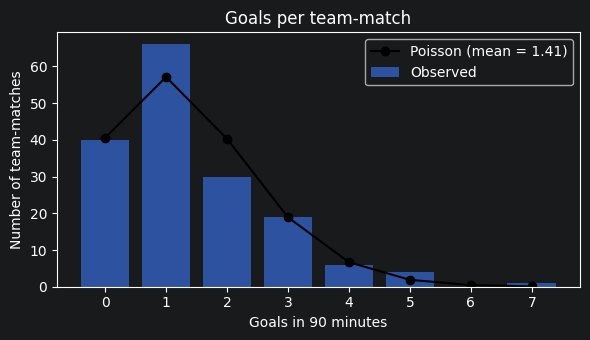

In [41]:
import matplotlib.pyplot as plt
from scipy.stats import poisson

y = train["goals_90"]
counts = y.value_counts().sort_index()
print(counts)
print(f"mean = {y.mean():.2f}, variance = {y.var():.2f}, var/mean = {y.var()/y.mean():.2f}")

k = np.arange(0, y.max() + 1)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(k, [counts.get(i, 0) for i in k], label="Observed", alpha=0.7)
ax.plot(k, poisson.pmf(k, y.mean()) * len(y), "o-", color="black",
        label=f"Poisson (mean = {y.mean():.2f})")      # pmf: probability of exactly k goals
ax.set(xlabel="Goals in 90 minutes", ylabel="Number of team-matches",
       title="Goals per team-match")
ax.legend();plt.style.use('default'); plt.tight_layout(); plt.show()

Goals per 90 is right-skewed count( mean 1.41,var 1.65). Residuals wont be normal. goals are close to random-at-a-steady-rate, with a bit more spread. The extra spread mostly comes from strong teams thrashing weak ones.

OLS assumes every feature affects goals linearly. If a relationship curves, a straight-line coefficient misrepresents. LOWESS (locally weighted scatterplot smoothing) fits many small weighted straight lines to neighbouring points (here 60% of the data each) and joins them into a curve, revealing the relationship's shape without assuming it is linear.
A straight LOWESS curve supports OLS's linearity assumption; a bend signals a transform is needed, though the curve is unreliable at the edges where few points remain.

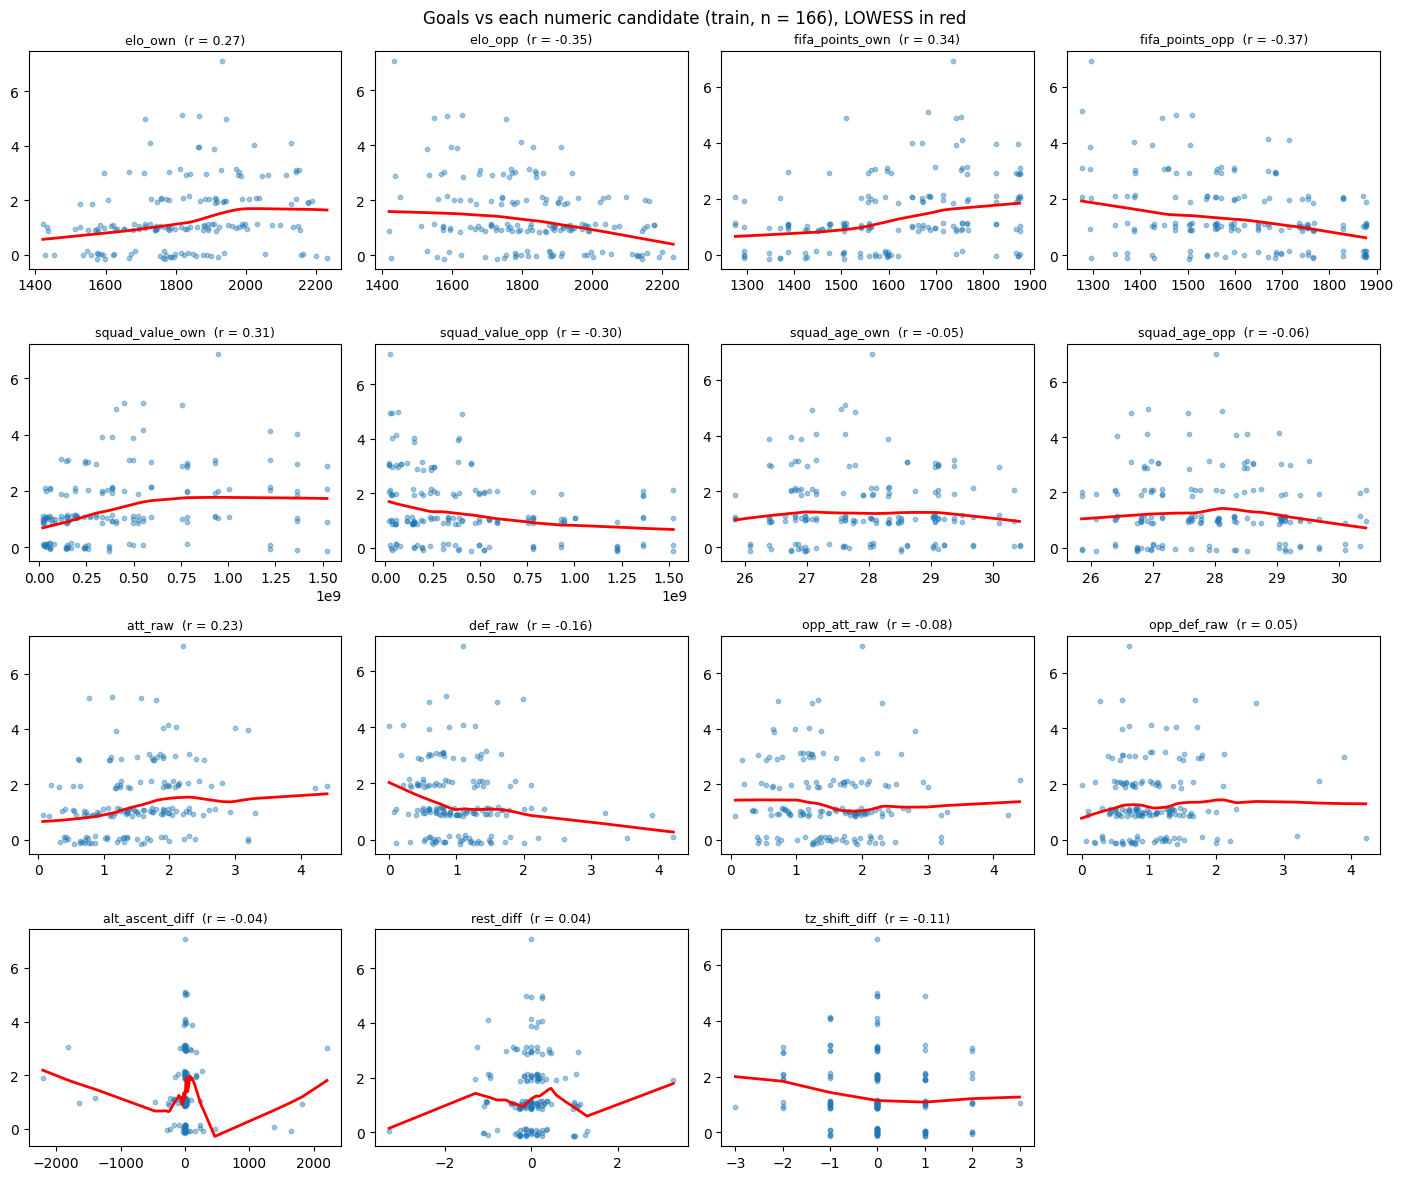

In [43]:
from statsmodels.nonparametric.smoothers_lowess import lowess

# Only continous features, features like home venue or knockout has 0 and 1
NUM = ["elo_own", "elo_opp", "fifa_points_own", "fifa_points_opp",
       "squad_value_own", "squad_value_opp", "squad_age_own", "squad_age_opp",
       "att_raw", "def_raw", "opp_att_raw", "opp_def_raw",
       "alt_ascent_diff", "rest_diff", "tz_shift_diff"]

rng_j = np.random.default_rng(SEED)
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for ax, col in zip(axes.flat, NUM):
    x, y = train[col], train["goals_90"]
    ax.scatter(x, y + rng_j.uniform(-0.15, 0.15, len(y)), s=10, alpha=0.4)
    sm = lowess(y, x, frac=0.6)               # smooth curve; frac = share of points used for each local fit
    ax.plot(sm[:, 0], sm[:, 1], color="red", lw=2)
    ax.set_title(f"{col}  (r = {x.corr(y):.2f})", fontsize=9)
axes.flat[-1].axis("off")                     # 16th panel unused
fig.suptitle("Goals vs each numeric candidate, LOWESS in red")
plt.tight_layout(); plt.show()

Strength features show roughly linear, symmetric own/opp effects (|r| 0.27–0.37; FIFA points slightly stronger than Elo), squad value is concave and right-skewed, opp_def_raw shows almost no link (r = 0.05), and squad age, altitude, rest and time-zone are near zero.
Squad value is log-transformed (concave, right-skewed), and own−opp difference encodings will be tested as strength pairs show roughly equal and opposite correlations.
Shrinkage is tested as a fix for the near-zero opp_def_raw link (r = 0.05)  and weak features (age, altitude, rest, time zone) stay as candidates for formal selection rather than being dropped by eye.

For knockout, stage_ord and the three home encodings, mean goals per group is compared with 95% confidence intervals and group sizes, the categorical counterpart of the LOWESS check.
Overlapping intervals indicate no clear difference, and groups with n < 10 are treated as uninformative.

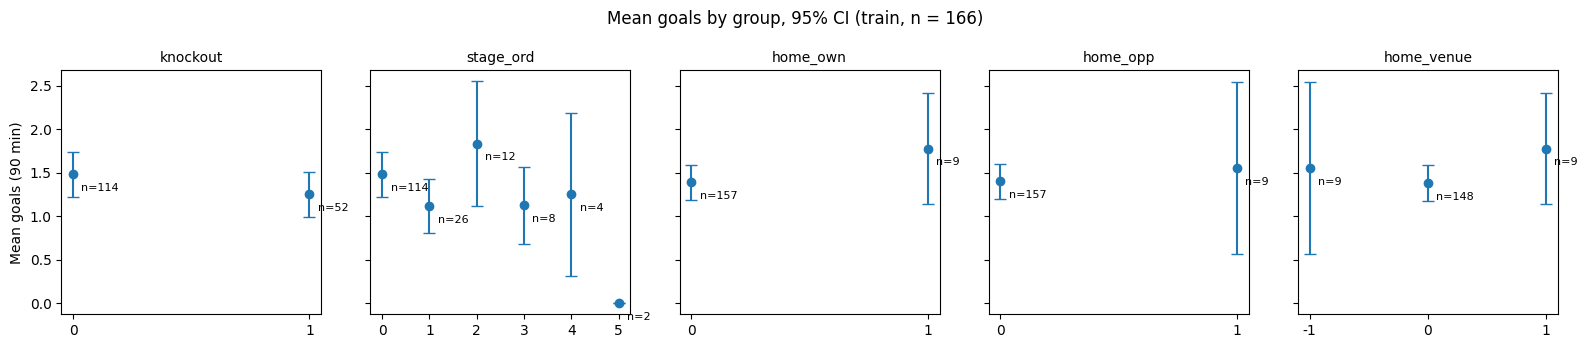

In [44]:
CAT = ["knockout", "stage_ord", "home_own", "home_opp", "home_venue"]

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5), sharey=True)
for ax, col in zip(axes, CAT):
    g = train.groupby(col)["goals_90"].agg(["mean", "std", "count"])      # per-group summary
    se = g["std"] / np.sqrt(g["count"])                                    # standard error of each group mean
    ax.errorbar(g.index.astype(str), g["mean"], yerr=1.96 * se, fmt="o", capsize=4)   # mean ± 95% CI
    for x, (m, n) in enumerate(zip(g["mean"], g["count"])):
        ax.annotate(f"n={n}", (x, m), textcoords="offset points", xytext=(6, -12), fontsize=8)
    ax.set_title(col, fontsize=10)
axes[0].set_ylabel("Mean goals (90 min)")
fig.suptitle("Mean goals by group, 95% CI")
plt.tight_layout(); plt.show()

 Knockout games average fewer goals (1.25 vs 1.48) but CIs overlap; stage_ord shows no consistent trend and rounds 3–5 have n ≤ 8; home groups have only n = 9 (hosts score 1.78, their opponents 1.56), too few to estimate a home effect reliably

Does two features carry same information? If yes, OLS cant separate it and the coefficients become unstable. We use correlation heatmap to find out this answer.

Variance Inflation factor to find out how a feature is predicted by all the others combined, which correlation often misses.

In [45]:
for side in ["own", "opp"]:
    train[f"log_squad_value_{side}"] = np.log(train[f"squad_value_{side}"])  # LOWESS suggests

POOL = ["elo_own", "elo_opp", "fifa_points_own", "fifa_points_opp",
        "log_squad_value_own", "log_squad_value_opp", "squad_age_own", "squad_age_opp",
        "att_raw", "def_raw", "opp_att_raw", "opp_def_raw",
        "alt_ascent_diff", "rest_diff", "tz_shift_diff", "knockout", "home_venue"]

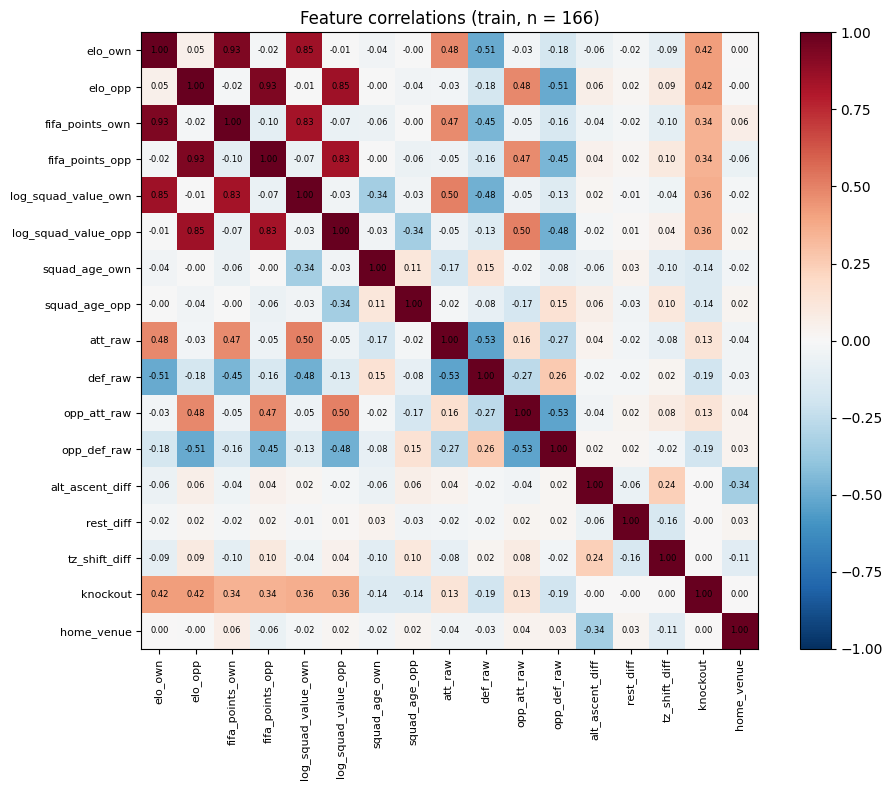

In [46]:
C = train[POOL].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1) # red = positive, blue = negative
ax.set_xticks(range(len(POOL)), POOL, rotation=90, fontsize=8)
ax.set_yticks(range(len(POOL)), POOL, fontsize=8)
for i in range(len(POOL)):
    for j in range(len(POOL)):
        ax.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im); ax.set_title("Feature correlations (train, n = 166)")
plt.tight_layout(); plt.show()

Elo, FIFA points and log squad value form a strength cluster within each side (r = 0.83–0.93), own and opponent features are nearly uncorrelated (|r| ≤ 0.10), knockout correlates with both Elos (0.42, stronger teams survive), and form features overlap strength only moderately (|r| ≈ 0.5).

In [47]:
#VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant
def vif_table(cols):
    X = add_constant(train[cols])                                  # VIF needs an intercept column
    return pd.Series([variance_inflation_factor(X.values, i + 1) for i in range(len(cols))],
                     index=cols).round(2).sort_values(ascending=False)   # i+1 skips the constant

print("VIF, full pool:\n", vif_table(POOL))

VIF, full pool:
 elo_own                11.67
elo_opp                11.67
fifa_points_own         8.68
fifa_points_opp         8.68
log_squad_value_own     5.98
log_squad_value_opp     5.98
def_raw                 1.83
opp_def_raw             1.83
att_raw                 1.76
opp_att_raw             1.76
squad_age_own           1.66
squad_age_opp           1.66
knockout                1.64
alt_ascent_diff         1.28
home_venue              1.25
tz_shift_diff           1.15
rest_diff               1.04
dtype: float64


With every candidate in one model, the strength measures are heavily redundant: Elo VIF 11.7 (≈91% explained by other features, SE ≈ 3.4× inflated), FIFA points 8.7 and log squad value 6.0, while all other features stay below 2. The full pool cannot be interpreted as a single OLS, so feature selection must keep at most one or two strength measures per side.

In [48]:
# a-priori baseline
B2_raw = ["elo_own", "elo_opp", "att_raw", "opp_def_raw",
          "log_squad_value_own", "log_squad_value_opp", "home_venue", "knockout"]
print("\nVIF, B2:\n", vif_table(B2_raw))


VIF, B2:
 elo_opp                4.03
elo_own                3.95
log_squad_value_own    3.82
log_squad_value_opp    3.74
opp_def_raw            1.56
knockout               1.54
att_raw                1.49
home_venue             1.01
dtype: float64


B2 is within acceptable limits (all VIF < 5), though Elo and log squad value (≈ 4, i.e. ≈75% shared information, SE ≈ 2× inflated) overlap as measures of team strength; form, knockout and home features are largely unique (VIF ≤ 1.56)

A heavily skewed feature pulls the OLS line around. The usual fix is a log.

In [49]:
NUM_SKEW = ["elo_own", "fifa_points_own", "squad_value_own", "log_squad_value_own",
            "squad_age_own", "att_raw", "def_raw",
            "alt_ascent_diff", "rest_diff", "tz_shift_diff"]  # own side only as VIF showed both values are identical

print(train[NUM_SKEW].skew().round(2).sort_values(key=abs, ascending=False))

def_raw                1.88
squad_value_own        1.17
att_raw                0.70
log_squad_value_own   -0.51
squad_age_own          0.25
fifa_points_own       -0.11
elo_own                0.04
alt_ascent_diff        0.00
rest_diff              0.00
tz_shift_diff          0.00
dtype: float64


def_raw/opp_def_raw are highly right-skewed (1.88) and squad value is skewed (1.17 → −0.51 after log); att_raw is moderate (0.70); difference features (altitude, rest, time zone) show skew 0 by construction (mirrored rows give x and −x), their issue being a spike at 0

              att_raw       def_raw      
                 mean count    mean count
team_match_no                            
1                1.97    38    0.82    38
2                1.31    38    1.21    38
3                1.11    38    1.39    38
4                1.50    26    0.95    26
5                1.72    12    0.89    12
6                1.91     8    0.83     8
7                2.00     4    0.56     4
8                1.90     2    0.41     2


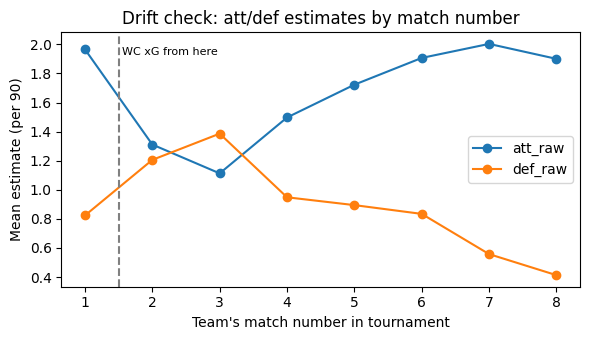

In [51]:
# Blended version of Xg, is the drift between the switch high?
d = train.groupby("team_match_no")[["att_raw", "def_raw"]].agg(["mean", "count"])
print(d.round(2))

fig, ax = plt.subplots(figsize=(6, 3.5))
for col, c in [("att_raw", "tab:blue"), ("def_raw", "tab:orange")]:
    ax.plot(d.index, d[(col, "mean")], "o-", color=c, label=col)
ax.axvline(1.5, ls="--", color="grey")                       # left: prior scale | right: WC xG scale
ax.text(1.55, ax.get_ylim()[1] * 0.95, "WC xG from here", fontsize=8, va="top")
ax.set(xlabel="Team's match number in tournament", ylabel="Mean estimate (per 90)",
       title="Drift check: att/def estimates by match number")
ax.legend(); plt.tight_layout(); plt.show()

We used average goals of last 10 competitive match for each team for their first match, but there is a huge difference between them. To minimize this, we can use a number to scale down, we will be using average goals in last two world cup. It is a limitation in our methodology, other viable options can be done in future.

In [52]:
WC_AVG = (2.64 + 2.69) / 2 / 2                        # goals per team per match, WC 2018 & 2022
first = df["team_match_no"] == 1
c_att = WC_AVG / df.loc[first, "prior_gf"].mean()
c_def = WC_AVG / df.loc[first, "prior_ga"].mean()
print(f"c_att = {c_att:.2f}, c_def = {c_def:.2f}")

for d in [train, test]:
    d["att_raw_c"]     = raw_rate(d["prior_gf"] * c_att,     d["sum_xg_before"],      d["min90_before"])
    d["def_raw_c"]     = raw_rate(d["prior_ga"] * c_def,     d["sum_xga_before"],     d["min90_before"])
    d["opp_att_raw_c"] = raw_rate(d["opp_prior_gf"] * c_att, d["opp_sum_xg_before"],  d["opp_min90_before"])
    d["opp_def_raw_c"] = raw_rate(d["opp_prior_ga"] * c_def, d["opp_sum_xga_before"], d["opp_min90_before"])
    d["first_match"]   = (d["team_match_no"] == 1).astype(int)

c_att = 0.65, c_def = 1.66


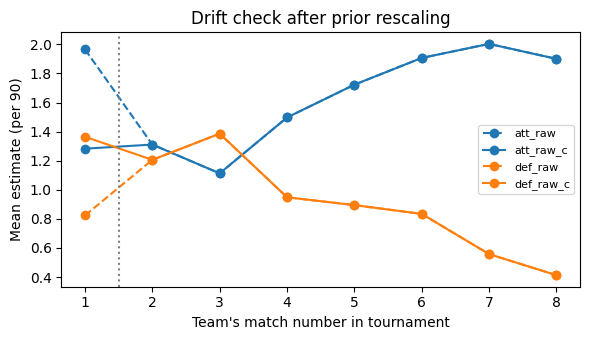

In [56]:
d = train.groupby("team_match_no")[["att_raw", "att_raw_c", "def_raw", "def_raw_c"]].mean()
fig, ax = plt.subplots(figsize=(6, 3.5))
for col, c, ls in [("att_raw", "tab:blue", "--"), ("att_raw_c", "tab:blue", "-"),
                   ("def_raw", "tab:orange", "--"), ("def_raw_c", "tab:orange", "-")]:
    ax.plot(d.index, d[col], "o", color=c, ls=ls, label=col)    # dashed = before, solid = after c fix
ax.axvline(1.5, ls=":", color="grey")
ax.set(xlabel="Team's match number in tournament", ylabel="Mean estimate (per 90)",
       title="Drift check after prior rescaling")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

The raw prior placed match-1 estimates on an inflated qualifier scale (att 1.97 vs ≈1.2 at matches 2–3; def 0.83 vs ≈1.3), a pure scale jump since matches 1–3 involve the same 48 teams; rescaling the prior by c_att = 0.65 and c_def = 1.66 (historical WC 1.33 goals per team per match ÷ mean prior of all 48 teams, leak-free) removes the jump.

OLS assumes goals rise in straight line with a feature, which LOWESS checked. Poisson assumes log(mean goals) rise in a straight line, meaning effects are multiplicative.

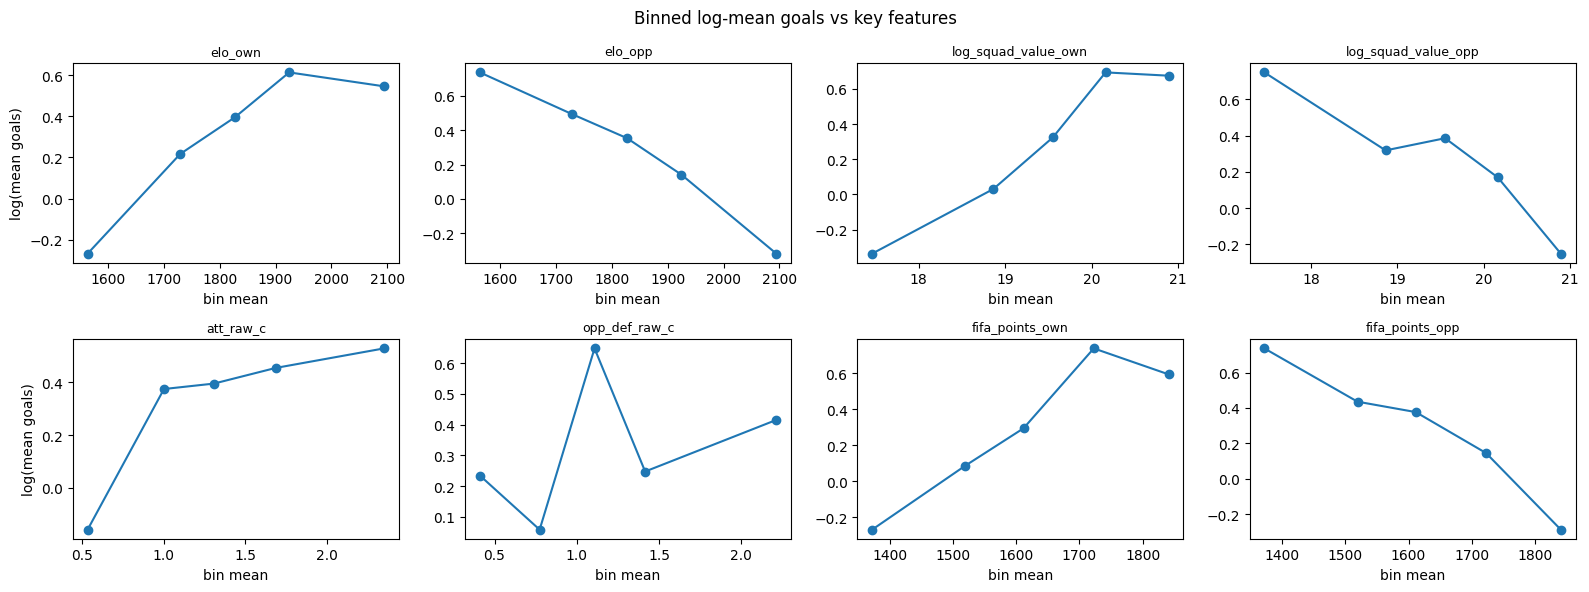

In [58]:
# Continuous B2 features (strength + form) plus FIFA points, binary and near-zero features are excluded as they have no shape to test.
KEY = ["elo_own", "elo_opp", "log_squad_value_own", "log_squad_value_opp",
       "att_raw_c", "opp_def_raw_c", "fifa_points_own", "fifa_points_opp"]

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.flat, KEY):
    bins = pd.qcut(train[col], q=5, duplicates="drop")
    g = train.groupby(bins, observed=True).agg(x=(col, "mean"), m=("goals_90", "mean"))
    ax.plot(g["x"], np.log(g["m"]), "o-")                          # straight = log-linear (Poisson shape)
    ax.set_title(col, fontsize=9); ax.set_xlabel("bin mean")
for ax in axes[:, 0]:
    ax.set_ylabel("log(mean goals)")
fig.suptitle("Binned log-mean goals vs key features")
plt.tight_layout(); plt.show()

Opponent-strength features are close to log-linear (constant percentage effect, supporting Poisson's form), own-strength features rise then plateau in the top quintile on both scales, att_raw_c is concave, and opp_def_raw_c shows no trend even after rescaling

## Feature Selection
